# Zero-Knowledge Proof Verification Module — walkthrough

Companion notebook for paper Sec. V-D ("Zero-Knowledge Proof Verification Module"). Every proof here is real elliptic-curve cryptography (`arca.layer2_identity.zkp_module`, built on `brainpoolP256r1` via `tinyec`) — not a mock — but it is a from-scratch Sigma-protocol construction, not a production zk-SNARK toolchain. See the module's docstring, and the note in `prove_membership`, for exactly what simplifications were made and why.

## 1. Pedersen commitments

`commit(m)` returns `C = m*G + r*H`, where `H`'s discrete log relative to `G` is unknown to everyone (derived via hash-to-curve) — this is what makes the commitment *binding*, not just hiding.

In [1]:
import sys, pathlib
REPO_ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from arca.layer2_identity import zkp_module as zkp

commitment, randomness = zkp.commit(42)
print('Committed point (x,y):', commitment.point.x, commitment.point.y)
print('The message (42) never appears in the commitment itself.')

Committed point (x,y): 50630063810561078603756457776737067778780702636541379093159683514282003647211 9952940673395885307666754877541214720422861625886332631204135704835846558143
The message (42) never appears in the commitment itself.


## 2. Schnorr NIZK proof of knowledge of the opening

Proves you know `(m, r)` behind a commitment, without revealing either.

In [2]:
proof = zkp.prove_opening(42, randomness, commitment)
print('Valid opening proof verifies:', zkp.verify_opening(commitment, proof))

wrong_proof = zkp.prove_opening(43, randomness, commitment)  # 43 != the committed 42
print('Proof for the WRONG message is rejected:', zkp.verify_opening(commitment, wrong_proof))

Valid opening proof verifies: True


Proof for the WRONG message is rejected: False


## 3. Disjunctive (OR) proof — privacy-preserving set membership

This is the actual predicate the paper's example uses: proving a jurisdiction is on an allow-list *without revealing which one*. Implemented as a Cramer-Damgård-Schoenmakers OR-composition of Schnorr proofs.

In [3]:
def encode_country(cc):
    return ord(cc[0]) * 256 + ord(cc[1])

allowed = [encode_country(c) for c in ['AU', 'US', 'GB', 'DE', 'FR', 'JP', 'SG', 'CA']]

# Alice's true jurisdiction is Australia -- she'll prove membership without revealing this
secret = encode_country('AU')
c, r = zkp.commit(secret)
membership_proof = zkp.prove_membership(secret, r, c, allowed)
print('Membership proof verifies:', zkp.verify_membership(membership_proof, allowed))
print('Proof object fields (no secret or index anywhere):', list(vars(membership_proof).keys()))

Membership proof verifies: True
Proof object fields (no secret or index anywhere): ['commitment', 'branches', 'global_challenge']


In [4]:
# Soundness check: you provably cannot construct this proof for a value NOT in the allowed set.
banned = encode_country('KP')
c2, r2 = zkp.commit(banned)
try:
    zkp.prove_membership(banned, r2, c2, allowed)
    print('ERROR: should not have succeeded')
except ValueError as e:
    print('Correctly refused:', e)

Correctly refused: message is not in allowed_values — cannot prove a false statement


## 4. Why the allow-list stays small: the proof cost scales O(n)

This OR-proof does real elliptic-curve scalar multiplication work per candidate value. That's fine for a curated allow-list of tens of jurisdictions (a realistic compliance policy for one asset offering) but does **not** scale to enumerating all ~195 sovereign states — see `jurisdiction_agent.allowed_jurisdiction_set`'s docstring. Below: proof generation time vs. allow-list size, measured directly.

In [5]:
import time

sizes = [2, 4, 8, 16, 32]
timings = []
for n in sizes:
    pool = [encode_country(f'{chr(65+i)}{chr(65+(i+1)%26)}') for i in range(n)]
    secret_n = pool[0]
    c_n, r_n = zkp.commit(secret_n)
    t0 = time.time()
    p_n = zkp.prove_membership(secret_n, r_n, c_n, pool)
    zkp.verify_membership(p_n, pool)
    timings.append(time.time() - t0)

list(zip(sizes, [round(t, 4) for t in timings]))

[(2, 0.2006), (4, 0.4386), (8, 0.9656), (16, 2.0335), (32, 4.1708)]

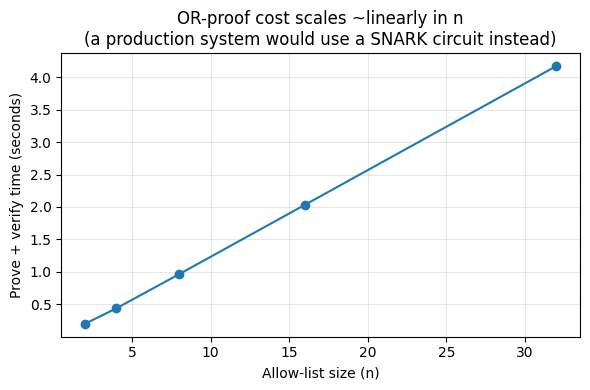

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(sizes, timings, marker='o')
plt.xlabel('Allow-list size (n)')
plt.ylabel('Prove + verify time (seconds)')
plt.title('OR-proof cost scales ~linearly in n\n(a production system would use a SNARK circuit instead)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(REPO_ROOT / 'notebooks' / 'zkp_scaling.png', dpi=120, bbox_inches='tight')
plt.show()